In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import os
import matplotlib.pyplot as plt

data = pd.read_excel('well_time_data.xlsx')

In [11]:
data

,time,well_I_BHP,well_I_BHT,well_P_BHP,well_P_BHT,well_I_perf_0_molar_rate_wat,well_I_perf_0_molar_rate_gas,well_I_perf_1_molar_rate_wat,well_I_perf_1_molar_rate_gas,well_I_perf_2_molar_rate_wat,...,well_P_perf_0_advective_heat_rate_wat,well_P_perf_0_advective_heat_rate_gas,well_I_advective_heat_rate_wat_by_sum_perfs,well_I_advective_heat_rate_gas_by_sum_perfs,well_P_advective_heat_rate_wat_by_sum_perfs,well_P_advective_heat_rate_gas_by_sum_perfs,well_I_advective_heat_rate_wat_at_wh,well_I_advective_heat_rate_gas_at_wh,well_P_advective_heat_rate_wat_at_wh,well_P_advective_heat_rate_gas_at_wh
0,0.000100,198.545650,300,152.429532,349.842250,-94967.280216,0,-0.001061,0,-76782.034077,...,-1.510732e+09,0,2.874551e+08,0,-1.510732e+09,0,2.905993e+08,0,-1.508982e+09,0
1,0.000220,198.883364,300,147.856051,349.866548,-56555.303868,0,-0.000693,0,-29541.698395,...,-1.509820e+09,0,2.921084e+08,0,-1.509820e+09,0,2.906015e+08,0,-1.509491e+09,0
2,0.000364,199.086818,300,145.586164,349.854881,-35314.440664,0,-0.000447,0,-4239.503053,...,-1.509346e+09,0,2.914437e+08,0,-1.509346e+09,0,2.906029e+08,0,-1.509163e+09,0
3,0.000537,199.229250,300,144.268396,349.845821,-20646.396809,0,-0.000259,0,12829.678054,...,-1.509071e+09,0,2.867252e+08,0,-1.509071e+09,0,2.906038e+08,0,-1.508917e+09,0
4,0.000744,199.339701,300,143.457974,349.839987,-9044.357237,0,-0.000105,0,26249.246757,...,-1.508902e+09,0,2.905534e+08,0,-1.508902e+09,0,2.906045e+08,0,-1.508759e+09,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191,21184.500000,232.555130,300,176.476879,331.464813,198273.278694,0,0.002069,0,299281.731178,...,-1.060113e+09,0,2.908222e+08,0,-1.060113e+09,0,2.908222e+08,0,-1.059981e+09,0
192,21384.500000,232.861372,300,176.783150,331.376041,198273.884672,0,0.002069,0,299282.645878,...,-1.057946e+09,0,2.908242e+08,0,-1.057946e+09,0,2.908243e+08,0,-1.057814e+09,0
193,21549.750000,233.114404,300,177.036206,331.303523,198274.385000,0,0.002069,0,299283.401086,...,-1.056176e+09,0,2.908258e+08,0,-1.056176e+09,0,2.908259e+08,0,-1.056044e+09,0
194,21749.750000,233.420645,300,177.342476,331.216947,198274.990975,0,0.002069,0,299284.315782,...,-1.054063e+09,0,2.908279e+08,0,-1.054063e+09,0,2.908279e+08,0,-1.053931e+09,0


In [2]:
Measured_depth = 2500 #meters

#CAPEX
Drilling_costs = 375000 +1150*Measured_depth +0.3*(Measured_depth)**2

Construction_costs = 0.5*Drilling_costs
Site_preparation_costs = 0.1*Drilling_costs
Equipment_costs = 0.2*Drilling_costs 

Capex = Drilling_costs + Construction_costs + Site_preparation_costs + Equipment_costs


#OPEX is 10% of CAPEX per year
Opex = 0.1 * Capex

#ABEX 
Abex = 0.05 * Capex

#CASHFLOW


revenue = 0
expenses =0
unit_price =0.1 #EUR/kWh
cum_production =0
operating_costs =0
capital_costs =0
royalty_rate =0
tax_rate =0.25
income_before_tax =0

cash_flow_in_year_k = revenue - expenses 
cash_flow_in_year_k = (unit_price * cum_production ) - (operating_costs + capital_costs) - (royalty_rate * unit_price *  cum_production) - (income_before_tax * tax_rate )

print("CAPEX: ", Capex /1e6, "million EUR")


CAPEX:  9.225 million EUR


In [ ]:
# Array of annual system Power in MW from Year 1 to Year 60
data_60_years = data['Power_MW'].values[:60]


In [4]:
#Array of MWh of energy per year from Year 1 to Year 60


MWh = [
    35557.544870,
    35556.931177,
    35556.443997,
    35556.130896,
    35555.936123,
    35555.830991,
    35555.789027,
    35555.774310,
    35555.728290,
    35555.555029,
    35555.107284,
    35554.176844,
    35552.491811,
    35549.721719,
    35545.489931,
    35539.391389,
    35531.013049,
    35519.954437,
    35505.846130,
    35488.364675,
    35467.243227,
    35442.277763,
    35413.329232,
    35380.322282,
    35343.241318,
    35302.124697,
    35257.057755,
    35208.165314,
    35155.604127,
    35099.555650,
    35040.219354,
    34977.806782,
    34912.536365,
    34844.629052,
    34774.304724,
    34701.779306,
    34627.262549,
    34550.956363,
    34473.053625,
    34393.737418,
    34313.180582,
    34231.545525,
    34148.984257,
    34065.638571,
    33981.640339,
    33897.111902,
    33812.166493,
    33726.908720,
    33641.435032,
    33555.834215,
    33470.187876,
    33384.570899,
    33299.051894,
    33213.693638,
    33128.553455,
    33043.683613,
    32959.131685,
    32874.940871,
    32791.150316,
]

MWh_array = np.array(MWh)

# Calculate revenue for all years
Revenue = MWh_array * unit_price * 1000 

# Print only Year 1 (index 0)
print( Revenue, "EUR")


[3555754.487  3555693.1177 3555644.3997 3555613.0896 3555593.6123
 3555583.0991 3555578.9027 3555577.431  3555572.829  3555555.5029
 3555510.7284 3555417.6844 3555249.1811 3554972.1719 3554548.9931
 3553939.1389 3553101.3049 3551995.4437 3550584.613  3548836.4675
 3546724.3227 3544227.7763 3541332.9232 3538032.2282 3534324.1318
 3530212.4697 3525705.7755 3520816.5314 3515560.4127 3509955.565
 3504021.9354 3497780.6782 3491253.6365 3484462.9052 3477430.4724
 3470177.9306 3462726.2549 3455095.6363 3447305.3625 3439373.7418
 3431318.0582 3423154.5525 3414898.4257 3406563.8571 3398164.0339
 3389711.1902 3381216.6493 3372690.872  3364143.5032 3355583.4215
 3347018.7876 3338457.0899 3329905.1894 3321369.3638 3312855.3455
 3304368.3613 3295913.1685 3287494.0871 3279115.0316] EUR


Total CAPEX: 9.22 million EUR
Annual OPEX: 0.92 million EUR
Break-even occurs in Year: 10
Net Present Value (Undiscounted) at Year 60: 133.67 million EUR


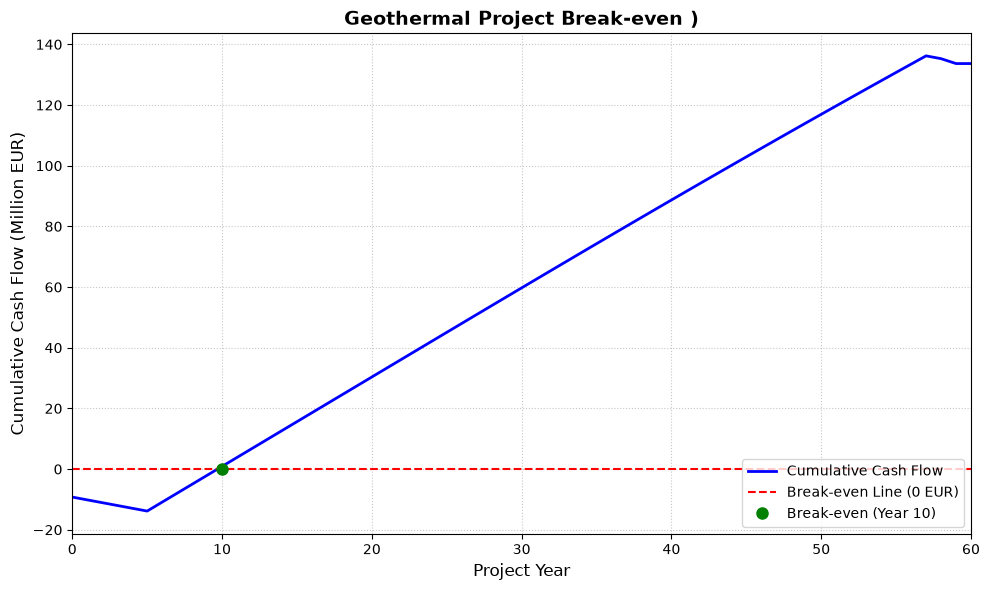

In [5]:

Measured_depth = 2500 # meters
Drilling_costs = 375000 + 1150 * Measured_depth + 0.3 * (Measured_depth)**2
Construction_costs = 0.5 * Drilling_costs
Site_preparation_costs = 0.1 * Drilling_costs
Equipment_costs = 0.2 * Drilling_costs 

Capex = Drilling_costs + Construction_costs + Site_preparation_costs + Equipment_costs


Opex = 0.1 * Capex   # OPEX is 10% of CAPEX every year
Abex = 0.15 * Capex  # ABEX is 5% of CAPEX incurred at the end of life (Year 60)


unit_price = 0.15    # EUR/kWh
royalty_rate = 0.10  # 2% standard subsurface royalty estimate
tax_rate = 0.25     # 25.8% standard Dutch corporate tax rate

print(f"Total CAPEX: {Capex / 1e6:.2f} million EUR")
print(f"Annual OPEX: {Opex / 1e6:.2f} million EUR")

# --- 4. PRODUCTION ARRAY (Year 1 to 60) ---
MWh = [
    0,0,0,0,0,35557.544870, 35556.931177, 35556.443997, 35556.130896, 35555.936123,
    35555.830991, 35555.789027, 35555.774310, 35555.728290, 35555.555029,
    35555.107284, 35554.176844, 35552.491811, 35549.721719, 35545.489931,
    35539.391389, 35531.013049, 35519.954437, 35505.846130, 35488.364675,
    35467.243227, 35442.277763, 35413.329232, 35380.322282, 35343.241318,
    35302.124697, 35257.057755, 35208.165314, 35155.604127, 35099.555650,
    35040.219354, 34977.806782, 34912.536365, 34844.629052, 34774.304724,
    34701.779306, 34627.262549, 34550.956363, 34473.053625, 34393.737418,
    34313.180582, 34231.545525, 34148.984257, 34065.638571, 33981.640339,
    33897.111902, 33812.166493, 33726.908720, 33641.435032, 33555.834215,
    33470.187876, 33384.570899, 0, 0, 
]
MWh_array = np.array(MWh)

# --- 5. CASH FLOW MODELING (Year 0 to 60) ---
years = np.arange(0, 61) # 61 elements (Year 0 through Year 60)
annual_cash_flows = np.zeros(61)

# Year 0: Investment occurs before production begins
annual_cash_flows[0] = -Capex

# Straight-line depreciation of CAPEX over 60 years
annual_depreciation = Capex / 60 

for i, prod_MWh in enumerate(MWh_array):
    year = i + 1
    
    # 1 MWh = 1000 kWh
    annual_revenue = prod_MWh * 1000 * unit_price
    
    # Deduct Royalties
    royalties = annual_revenue * royalty_rate
    
    # Earnings Before Interest, Taxes, Depreciation, and Amortization (EBITDA)
    ebitda = annual_revenue - Opex - royalties
    
    # Taxable Income = EBITDA minus Depreciation
    income_before_tax = ebitda - annual_depreciation
    
    # Calculate Corporate Tax (cannot be negative)
    tax = max(0, income_before_tax * tax_rate)
    
    # Net Operating Cash Flow
    net_cash_flow = ebitda - tax
    

        
 

    if year in [59, 60]:
        net_cash_flow -= (Abex / 2)
            
        # Add operating cash flow
    annual_cash_flows[year] += net_cash_flow

# Calculate cumulative cash flows for the break-even plot
cumulative_cash_flows = np.cumsum(annual_cash_flows)

# Determine Break-even Year (first year where cumulative cash flow turns positive)
break_even_year = np.argmax(cumulative_cash_flows > 0)
print(f"Break-even occurs in Year: {break_even_year}")
print(f"Net Present Value (Undiscounted) at Year 60: {cumulative_cash_flows[-1] / 1e6:.2f} million EUR")

# --- 6. BREAK-EVEN PLOT ---
plt.figure(figsize=(10, 6))

# Plot the cumulative cash flow line
plt.plot(years, cumulative_cash_flows / 1e6, color='b', linewidth=2, label='Cumulative Cash Flow')

# Plot the zero-line (break-even line)
plt.axhline(0, color='r', linestyle='--', label='Break-even Line (0 EUR)')

# Highlight the break-even point
plt.plot(break_even_year, 0, 'go', markersize=8, label=f'Break-even (Year {break_even_year})')

# Formatting
plt.title('Geothermal Project Break-even )', fontsize=14, fontweight='bold')
plt.xlabel('Project Year', fontsize=12)
plt.ylabel('Cumulative Cash Flow (Million EUR)', fontsize=12)
plt.xlim(0, 60)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='lower right')
plt.tight_layout()

# Show the plot
plt.show()

In [6]:
# Changed ABEX to 30% of CAPEX as requested
Abex = 0.30 * Capex

# ... (MWh array padding logic remains the same) ...

def calculate_cash_flow(unit_price, royalty_rate):
    annual_cash_flows = np.zeros(61)
    
    # Spread CAPEX evenly across the first 10 years (Years 0 to 9)
    for year in range(10):
        annual_cash_flows[year] -= Capex / 10
        
    annual_depreciation = Capex / 60 

    for i, prod_MWh in enumerate(MWh_array):
        year = i + 1
        annual_revenue = prod_MWh * 1000 * unit_price
        royalties = annual_revenue * royalty_rate
        ebitda = annual_revenue - Opex - royalties
        income_before_tax = ebitda - annual_depreciation
        tax = max(0, income_before_tax * 0.25)
        net_cash_flow = ebitda - tax
        
        # --- NEW ABEX LOGIC ---
        # Spread Abex over the last 2 years (Years 59 and 60)
        if year in [59, 60]:
            net_cash_flow -= (Abex / 2)
            
        # Add operating cash flow
        annual_cash_flows[year] += net_cash_flow
        
    return np.cumsum(annual_cash_flows)

59


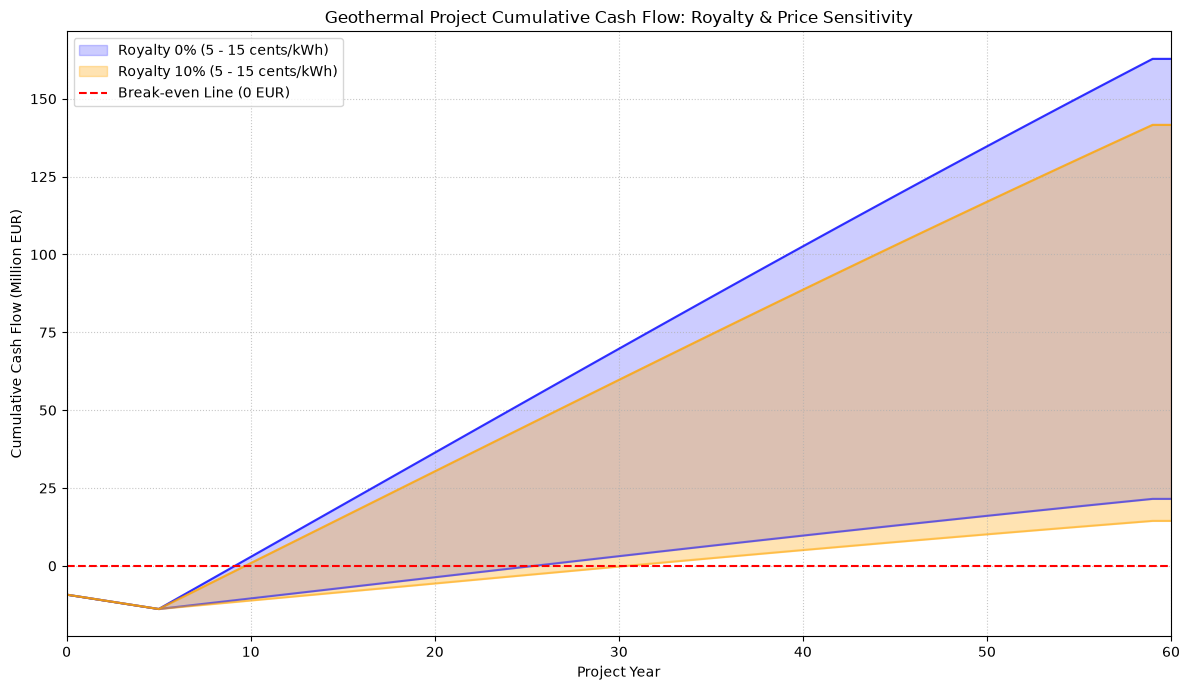

In [7]:
import numpy as np
import matplotlib.pyplot as plt

Measured_depth = 2500
Drilling_costs = 375000 + 1150 * Measured_depth + 0.3 * (Measured_depth)**2
Construction_costs = 0.5 * Drilling_costs
Site_preparation_costs = 0.1 * Drilling_costs
Equipment_costs = 0.2 * Drilling_costs 

Capex = Drilling_costs + Construction_costs + Site_preparation_costs + Equipment_costs
Opex = 0.1 * Capex
Abex =  0.05 * Capex

# Let's count MWh array length
MWh = [
    0,0,0,0,0,35557.544870, 35556.931177, 35556.443997, 35556.130896, 35555.936123,
    35555.830991, 35555.789027, 35555.774310, 35555.728290, 35555.555029,
    35555.107284, 35554.176844, 35552.491811, 35549.721719, 35545.489931,
    35539.391389, 35531.013049, 35519.954437, 35505.846130, 35488.364675,
    35467.243227, 35442.277763, 35413.329232, 35380.322282, 35343.241318,
    35302.124697, 35257.057755, 35208.165314, 35155.604127, 35099.555650,
    35040.219354, 34977.806782, 34912.536365, 34844.629052, 34774.304724,
    34701.779306, 34627.262549, 34550.956363, 34473.053625, 34393.737418,
    34313.180582, 34231.545525, 34148.984257, 34065.638571, 33981.640339,
    33897.111902, 33812.166493, 33726.908720, 33641.435032, 33555.834215,
    33470.187876, 33384.570899, 33299.051894, 33213.693638,
]
MWh_array = np.array(MWh)
print(len(MWh_array))

# Function to calculate cash flows
def calculate_cash_flow(unit_price, royalty_rate):
    annual_cash_flows = np.zeros(61)
    annual_cash_flows[0] = -Capex
    annual_depreciation = Capex / 60 

    for i, prod_MWh in enumerate(MWh_array):
        year = i + 1
        annual_revenue = prod_MWh * 1000 * unit_price
        royalties = annual_revenue * royalty_rate
        ebitda = annual_revenue - Opex - royalties
        income_before_tax = ebitda - annual_depreciation
        tax = max(0, income_before_tax * 0.25)
        net_cash_flow = ebitda - tax
        if year == 60:
            net_cash_flow -= Abex
        annual_cash_flows[year] = net_cash_flow
    return np.cumsum(annual_cash_flows)

prices = [0.05, 0.15]
cf_0_low = calculate_cash_flow(0.05, 0.0)
cf_0_high = calculate_cash_flow(0.15, 0.0)
cf_10_low = calculate_cash_flow(0.05, 0.10)
cf_10_high = calculate_cash_flow(0.15, 0.10)

plt.figure(figsize=(12, 7))
years = np.arange(0, 61)

# Royalty 0% range
plt.fill_between(years, cf_0_low / 1e6, cf_0_high / 1e6, color='blue', alpha=0.2, label='Royalty 0% (5 - 15 cents/kWh)')
plt.plot(years, cf_0_low / 1e6, color='blue', linestyle='-', alpha=0.5)
plt.plot(years, cf_0_high / 1e6, color='blue', linestyle='-', alpha=0.8)

# Royalty 10% range
plt.fill_between(years, cf_10_low / 1e6, cf_10_high / 1e6, color='orange', alpha=0.3, label='Royalty 10% (5 - 15 cents/kWh)')
plt.plot(years, cf_10_low / 1e6, color='orange', linestyle='-', alpha=0.5)
plt.plot(years, cf_10_high / 1e6, color='orange', linestyle='-', alpha=0.8)

plt.axhline(0, color='red', linestyle='--', label='Break-even Line (0 EUR)')
plt.title('Geothermal Project Cumulative Cash Flow: Royalty & Price Sensitivity')
plt.xlabel('Project Year')
plt.ylabel('Cumulative Cash Flow (Million EUR)')
plt.xlim(0, 60)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('cash_flow_plot.png')

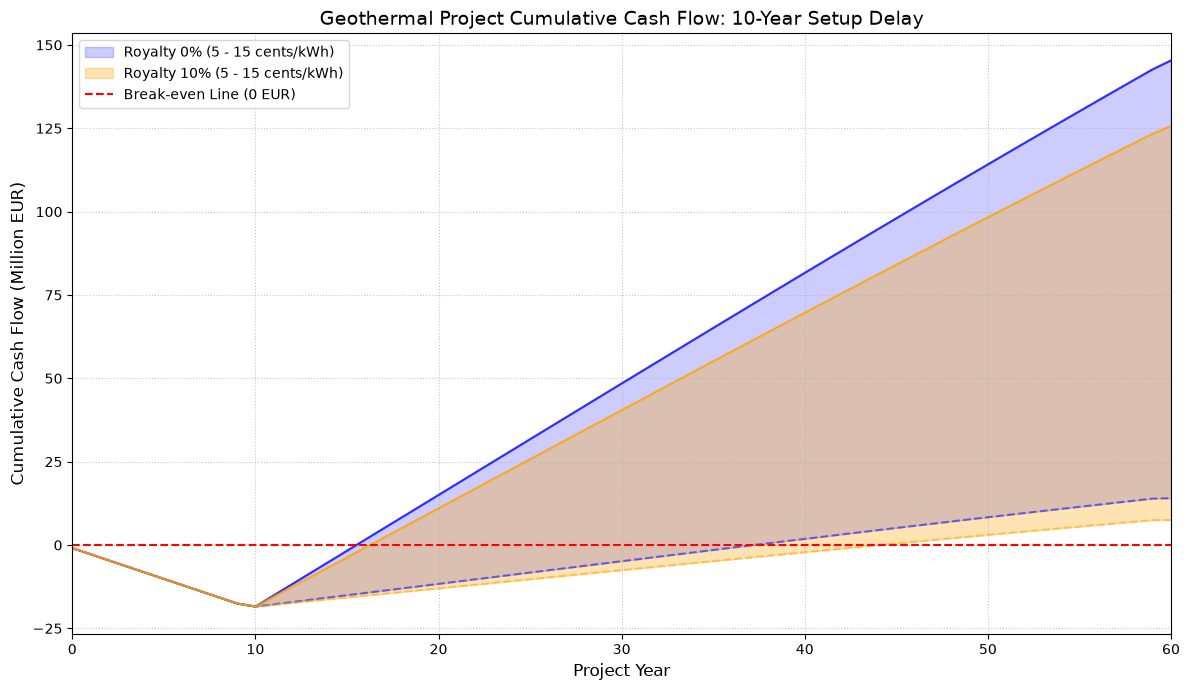

In [8]:
import numpy as np
import matplotlib.pyplot as plt

Measured_depth = 2500
Drilling_costs = 375000 + 1150 * Measured_depth + 0.3 * (Measured_depth)**2
Construction_costs = 0.5 * Drilling_costs
Site_preparation_costs = 0.1 * Drilling_costs
Equipment_costs = 0.2 * Drilling_costs 

Capex = Drilling_costs + Construction_costs + Site_preparation_costs + Equipment_costs
Opex = 0.1 * Capex
Abex =  0.05 * Capex

# First 10 years of zero production, followed by 50 years of production (Total = 60 years)
prod_values = [
    35557.544870, 35556.931177, 35556.443997, 35556.130896, 35555.936123,
    35555.830991, 35555.789027, 35555.774310, 35555.728290, 35555.555029,
    35555.107284, 35554.176844, 35552.491811, 35549.721719, 35545.489931,
    35539.391389, 35531.013049, 35519.954437, 35505.846130, 35488.364675,
    35467.243227, 35442.277763, 35413.329232, 35380.322282, 35343.241318,
    35302.124697, 35257.057755, 35208.165314, 35155.604127, 35099.555650,
    35040.219354, 34977.806782, 34912.536365, 34844.629052, 34774.304724,
    34701.779306, 34627.262549, 34550.956363, 34473.053625, 34393.737418,
    34313.180582, 34231.545525, 34148.984257, 34065.638571, 33981.640339,
    33897.111902, 33812.166493, 33726.908720, 33641.435032, 33555.834215
]
MWh = [0] * 10 + prod_values
MWh_array = np.array(MWh)

# Function to calculate cash flows
def calculate_cash_flow(unit_price, royalty_rate):
    annual_cash_flows = np.zeros(61)
    
    # Spread CAPEX evenly across the first 10 years (Years 0 to 9)
    for year in range(10):
        annual_cash_flows[year] -= Capex / 10
        
    annual_depreciation = Capex / 60 

    for i, prod_MWh in enumerate(MWh_array):
        year = i + 1
        annual_revenue = prod_MWh * 1000 * unit_price
        royalties = annual_revenue * royalty_rate
        ebitda = annual_revenue - Opex - royalties
        income_before_tax = ebitda - annual_depreciation
        tax = max(0, income_before_tax * 0.25)
        net_cash_flow = ebitda - tax
        
        if year == 60:
            net_cash_flow -= Abex
            
        # Add operating cash flow; this preserves any CAPEX already subtracted for that year
        annual_cash_flows[year] += net_cash_flow
        
    return np.cumsum(annual_cash_flows)

cf_0_low = calculate_cash_flow(0.05, 0.0)
cf_0_high = calculate_cash_flow(0.15, 0.0)
cf_10_low = calculate_cash_flow(0.05, 0.10)
cf_10_high = calculate_cash_flow(0.15, 0.10)

plt.figure(figsize=(12, 7))
years = np.arange(0, 61)

# Royalty 0% range
plt.fill_between(years, cf_0_low / 1e6, cf_0_high / 1e6, color='blue', alpha=0.2, label='Royalty 0% (5 - 15 cents/kWh)')
plt.plot(years, cf_0_low / 1e6, color='blue', linestyle='--', alpha=0.5)
plt.plot(years, cf_0_high / 1e6, color='blue', linestyle='-', alpha=0.8)

# Royalty 10% range
plt.fill_between(years, cf_10_low / 1e6, cf_10_high / 1e6, color='orange', alpha=0.3, label='Royalty 10% (5 - 15 cents/kWh)')
plt.plot(years, cf_10_low / 1e6, color='orange', linestyle='--', alpha=0.5)
plt.plot(years, cf_10_high / 1e6, color='orange', linestyle='-', alpha=0.8)

plt.axhline(0, color='red', linestyle='--', label='Break-even Line (0 EUR)')
plt.title('Geothermal Project Cumulative Cash Flow: 10-Year Setup Delay', fontsize=14)
plt.xlabel('Project Year', fontsize=12)
plt.ylabel('Cumulative Cash Flow (Million EUR)', fontsize=12)
plt.xlim(0, 60)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()